In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score  

In [2]:
df = pd.read_csv("uber.csv")

print(df.head())
print("Shape:", df.shape)
print(df.info())     

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [3]:
df.drop(columns=['Unnamed: 0', 'key'], errors='ignore', inplace=True)

print(df.isnull().sum())

df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

print("Shape after cleaning:", df.shape)

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64
Shape after cleaning: (199999, 7)


C:\Users\Rutuja\AppData\Local\Temp\ipykernel_26660\931975890.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Unnamed: 0', 'key'], errors='ignore', inplace=True)
C:\Users\Rutuja\AppData\Local\Temp\ipykernel_26660\931975890.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)
C:\Users\Rutuja\AppData\Local\Temp\ipykernel_26660\931975890.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [4]:
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'],
    errors='coerce'
)

df.dropna(subset=['pickup_datetime'], inplace=True)

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['weekday'] = df['pickup_datetime'].dt.weekday

C:\Users\Rutuja\AppData\Local\Temp\ipykernel_26660\780748111.py:6: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['pickup_datetime'], inplace=True)
C:\Users\Rutuja\AppData\Local\Temp\ipykernel_26660\780748111.py:11: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['weekday'] = df['pickup_datetime'].dt.weekday


In [5]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians,
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))


df['distance_km'] = haversine(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

print(df[['fare_amount', 'distance_km']].head())

   fare_amount  distance_km
0          7.5     1.683323
1          7.7     2.457590
2         12.9     5.036377
3          5.3     1.661683
4         16.0     4.475450


         fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
count  199999.000000     199999.000000    199999.000000      199999.000000   
mean       11.359892        -72.527631        39.935881         -72.525292   
std         9.901760         11.437815         7.720558          13.117408   
min       -52.000000      -1340.648410       -74.015515       -3356.666300   
25%         6.000000        -73.992065        40.734796         -73.991407   
50%         8.500000        -73.981823        40.752592         -73.980093   
75%        12.500000        -73.967154        40.767158         -73.963658   
max       499.000000         57.418457      1644.421482        1153.572603   

       dropoff_latitude  passenger_count           hour            day  \
count     199999.000000    199999.000000  199999.000000  199999.000000   
mean          39.923890         1.684543      13.491387      15.704739   
std            6.794829         1.385995       6.515505       8.687377   
m

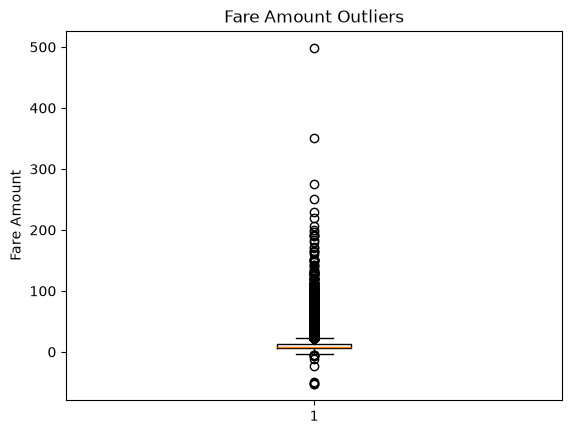

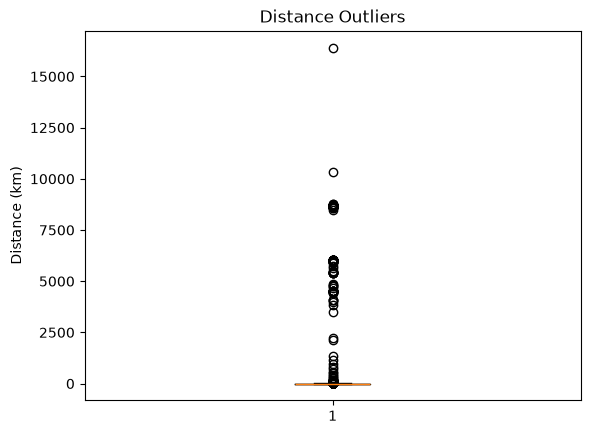

In [6]:
print(df.describe())

plt.boxplot(df['fare_amount'])
plt.title("Fare Amount Outliers")
plt.ylabel("Fare Amount")
plt.show()

plt.boxplot(df['distance_km'])
plt.title("Distance Outliers")
plt.ylabel("Distance (km)")
plt.show()

In [7]:
df = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'] > 0) &
    (df['passenger_count'] <= 6) &
    (df['pickup_latitude'].between(-90, 90)) &
    (df['dropoff_latitude'].between(-90, 90)) &
    (df['pickup_longitude'].between(-180, 180)) &
    (df['dropoff_longitude'].between(-180, 180)) &
    (df['distance_km'] > 0)
]

In [8]:
def remove_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return data[
        (data[column] >= lower) &
        (data[column] <= upper)
    ]


df = remove_outliers(df, 'fare_amount')
df = remove_outliers(df, 'distance_km')

print("Cleaned shape:", df.shape)

Cleaned shape: (169019, 12)


In [9]:
corr_columns = [
    'fare_amount',
    'distance_km',
    'passenger_count',
    'hour',
    'day',
    'month',
    'weekday'
]

correlation = df[corr_columns].corr()

print(correlation)

                 fare_amount  distance_km  passenger_count      hour  \
fare_amount         1.000000     0.795531         0.016702  0.006767   
distance_km         0.795531     1.000000         0.005739 -0.012971   
passenger_count     0.016702     0.005739         1.000000  0.016994   
hour                0.006767    -0.012971         0.016994  1.000000   
day                 0.004776     0.006004         0.002336  0.004906   
month               0.032687     0.007145         0.007943 -0.003245   
weekday             0.013184     0.036901         0.036983 -0.083751   

                      day     month   weekday  
fare_amount      0.004776  0.032687  0.013184  
distance_km      0.006004  0.007145  0.036901  
passenger_count  0.002336  0.007943  0.036983  
hour             0.004906 -0.003245 -0.083751  
day              1.000000 -0.015878  0.005293  
month           -0.015878  1.000000 -0.009897  
weekday          0.005293 -0.009897  1.000000  


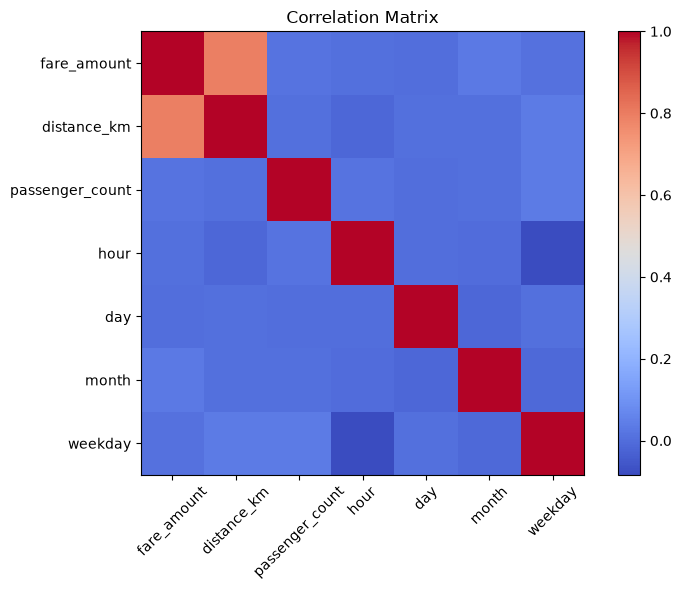

In [10]:
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation,
    cmap='coolwarm',
    interpolation='nearest'
)

plt.colorbar()

plt.xticks(
    range(len(corr_columns)),
    corr_columns,
    rotation=45
)

plt.yticks(
    range(len(corr_columns)),
    corr_columns
)

plt.title("Correlation Matrix")
plt.tight_layout()

plt.show()

In [11]:
features = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'passenger_count',
    'distance_km',
    'hour',
    'day',
    'month',
    'weekday'
]

X = df[features]
y = df['fare_amount']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 135215
Testing samples: 33804


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 135215
Testing samples: 33804


In [14]:
lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

lr_r2 = r2_score(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_mae = mean_absolute_error(y_test, lr_pred)

print("Linear Regression")
print("R2 :", lr_r2)
print("RMSE :", lr_rmse)
print("MAE :", lr_mae)

Linear Regression
R2 : 0.6411273253083991
RMSE : 2.2280309734488637
MAE : 1.6040470680841943


In [15]:
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_r2 = r2_score(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_mae = mean_absolute_error(y_test, rf_pred)

print("Random Forest Regression")
print("R2 :", rf_r2)
print("RMSE :", rf_rmse)
print("MAE :", rf_mae)

Random Forest Regression
R2 : 0.7010867674411381
RMSE : 2.033403650176912
MAE : 1.4444394984145654


In [16]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2': [lr_r2, rf_r2],
    'RMSE': [lr_rmse, rf_rmse],
    'MAE': [lr_mae, rf_mae]
})

print(results)

               Model        R2      RMSE       MAE
0  Linear Regression  0.641127  2.228031  1.604047
1      Random Forest  0.701087  2.033404  1.444439


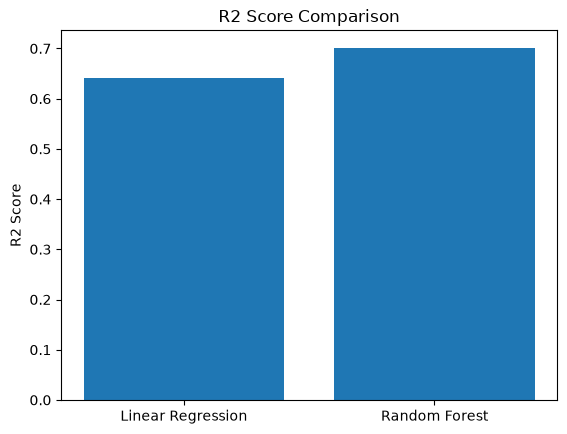

In [17]:
plt.bar(results['Model'], results['R2'])
plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.show()

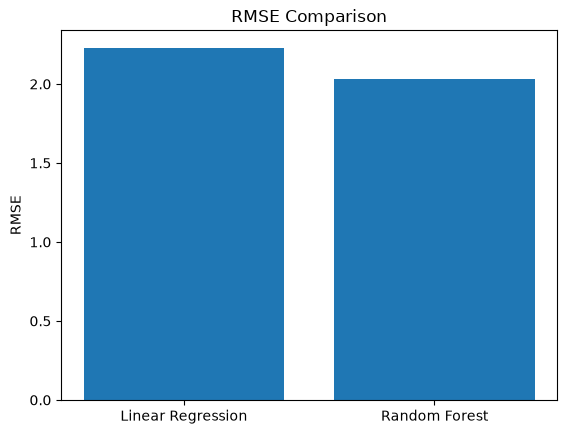

In [18]:
plt.bar(results['Model'], results['RMSE'])
plt.title("RMSE Comparison")
plt.ylabel("RMSE")
plt.show()

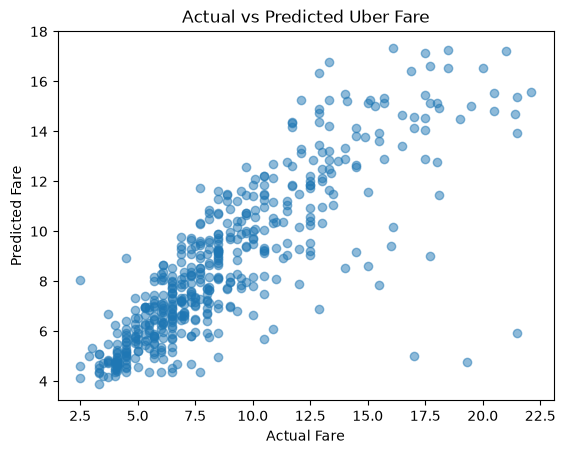

In [19]:
plt.scatter(
    y_test[:500],
    rf_pred[:500],
    alpha=0.5
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fare")

plt.show()

In [20]:
distance = haversine(
    40.73,
    -73.99,
    40.76,
    -73.97
)

new_ride = pd.DataFrame([{
    'pickup_longitude': -73.99,
    'pickup_latitude': 40.73,
    'dropoff_longitude': -73.97,
    'dropoff_latitude': 40.76,
    'passenger_count': 2,
    'distance_km': distance,
    'hour': 18,
    'day': 15,
    'month': 6,
    'weekday': 2
}])

predicted_fare = rf.predict(new_ride)

print("Predicted Fare = $", round(predicted_fare[0], 2))

Predicted Fare = $ 12.5
